Linear Regression, Perceptron, and Least Squares

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [2]:
# Data Generation for Regression

# Generate synthetic regression data
np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

In [3]:
# Task 1.3: Linear Regression (Gradient Descent)

def predict(X, w, b):
    """
    Computes the prediction of the linear regression model.
    """
    # IMPLEMENTED: y_hat = X * w + b
    y_hat = np.dot(X, w) + b
    return y_hat

def compute_cost(X, y, w, b):
    """
    Computes the Mean Squared Error (MSE) cost.
    """
    # IMPLEMENTED: Mean Squared Error (MSE)
    m = len(y)
    y_hat = predict(X, w, b)
    cost = (1 / m) * np.sum((y_hat - y) ** 2)
    return cost

def gradient_descent(X, y, w_init, b_init, alpha, epochs):
    """
    Performs gradient descent to learn w and b.
    """
    w, b = w_init, b_init
    m = len(y)
    
    for i in range(epochs):
        y_hat = predict(X, w, b)
        
        # IMPLEMENTED: Calculate gradients (dw, db) and update w, b
        dw = (2 / m) * np.dot(X.T, (y_hat - y))
        db = (2 / m) * np.sum(y_hat - y)
        
        w = w - alpha * dw
        b = b - alpha * db
        
    return w, b

# Example usage for Linear Regression (optional, for verification)
w_final, b_final = gradient_descent(X, y, w_init=np.zeros((1,1)), b_init=0, alpha=0.1, epochs=1000)
print(f"Linear Regression -> w: {w_final[0][0]:.4f}, b: {b_final:.4f}")

Linear Regression -> w: 2.7701, b: 4.2151


In [4]:
# Task 2.3: Least Squares (Normal Equation)

# Generate classification data (Labels: -1 and 1)
X_p, y_p = make_blobs(n_samples=200, centers=2, n_features=2, random_state=42)
y_p = np.where(y_p == 0, -1, 1).reshape(-1, 1)

# IMPLEMENTED: Add bias term (column of ones) to X_p
# We use np.c_ to concatenate a column of 1s to the feature matrix
X_with_bias = np.c_[np.ones((X_p.shape[0], 1)), X_p]

# IMPLEMENTED: Solve using Normal Equation: w = (X^T X)^-1 X^T y
# Using np.linalg.inv for matrix inversion and @ for matrix multiplication
w_lsp = np.linalg.inv(X_with_bias.T @ X_with_bias) @ X_with_bias.T @ y_p

print(f"Least Squares Weights:\n{w_lsp}")

Least Squares Weights:
[[ 0.57493139]
 [ 0.13726886]
 [-0.1303984 ]]


In [5]:
# Task 3.3: Perceptron Algorithm

def perceptron_train(X, y, eta=0.1, epochs=10):
    """
    Trains a Perceptron model using the learning rule.
    """
    n_samples, n_features = X.shape
    
    # IMPLEMENTED: Initialize weights (including bias) with zeros
    # Note: The problem defines w size as n_features + 1
    w = np.zeros(n_features + 1)
    
    # Add bias column to X
    X_b = np.c_[np.ones((n_samples, 1)), X]
    
    # Ensure y is a 1D array for element-wise operations below
    y = y.ravel()
    
    for _ in range(epochs):
        for i in range(n_samples):
            # IMPLEMENTED: Check the condition for misclassification
            # Hint: y_i * (w * x_i) <= 0
            # Since w and X_b[i] are arrays, we use dot product
            if y[i] * np.dot(w, X_b[i]) <= 0:
                # IMPLEMENTED: Update weights
                w = w + eta * y[i] * X_b[i]
                
    # Return weights as a column vector to match standard conventions 
    # and subsequent code requirements
    return w.reshape(-1, 1)

w_perceptron = perceptron_train(X_p, y_p)
print(f"Perceptron Weights:\n{w_perceptron}")

Perceptron Weights:
[[ 0.1       ]
 [ 0.99959474]
 [-0.52230523]]


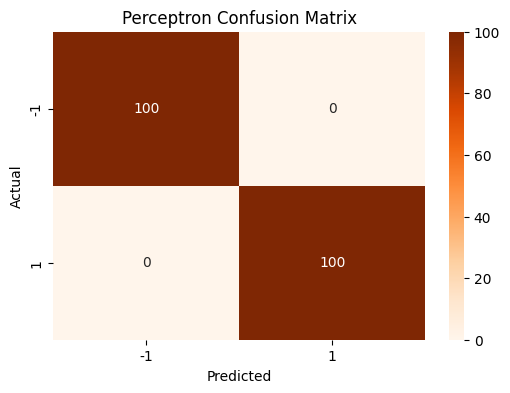


Classification Report:

              precision    recall  f1-score   support

          -1       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       100

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



In [6]:
# Task 4.3: Evaluation and Confusion Matrix

# IMPLEMENTED: Generate predictions (sign of X_b * w)
X_p_b = np.c_[np.ones((X_p.shape[0], 1)), X_p]
# Note: w_perceptron is a column vector, X_p_b is a matrix
y_pred = np.sign(X_p_b @ w_perceptron)

# IMPLEMENTED: Compute confusion matrix
cm = confusion_matrix(y_p, y_pred)

# Plotting the confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=['-1', '1'], 
            yticklabels=['-1', '1'])
plt.title("Perceptron Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_p, y_pred))
